# 02 - QA/QC and Standardization

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/02_qaqc_and_standardization.ipynb)

**Part A - Foundations - Petrophys Curriculum**

Raw logs are never quite ready for interpretation. Curves carry inconsistent names, mixed
units, physically impossible spikes, and intervals where the borehole itself was too poor
for the tool to read correctly. **Data conditioning** - QA/QC - fixes these before any
physics runs. Garbage in, garbage out is nowhere more true than in petrophysics.

This lesson works through the `petrophys.preprocessing` toolkit:

1. **Curve standardization** - map messy mnemonics to standard names, convert units.
2. **Value-range QC** - null out physically impossible values.
3. **Bad-hole / washout detection** - flag intervals where the borehole is unreliable.
4. **Multi-well normalization** - put a curve on a common scale across a field.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Standardize mnemonics and units with `CurveStandardizer` / `standardize_curves` and the
  `ALIAS_MAP`.
- Recognize a wrong unit label on core saturation and declare the right one with
  `standardize_core_saturation`.
- Apply value-range QC with `apply_value_range_qc` and read its `value_range_qc_note`.
- Detect washout / bad hole from **caliper (`CALI`)** vs **bit size (`BS`)** with
  `detect_washout` / `WashoutDetection`, and set the bad-hole thresholds of `pp.interpret`.
- Normalize a curve across wells with `NormalizationModule`, and understand *why* multi-well
  normalization is needed.
- See **before/after** for each step and be able to justify every QC decision.

## Why this matters

- **Standardization** lets one workflow run over a whole field: if every well calls its
  deep resistivity something different (`RT`, `ILD`, `LLD`, ...), no batch process can find
  it. Mapping them all to `RDEP` fixes that.
- **Value-range QC** removes non-physical readings (a neutron porosity of 3.0, a negative
  gamma ray) that would otherwise poison averages and crossplots.
- **Bad-hole detection** protects density-based answers. Where the hole washes out, the
  density pad loses contact and `RHOB` reads too low - which would fake high porosity. The
  caliper-minus-bit-size, $\mathrm{CALI}-\mathrm{BS}$, is the classic washout indicator.
- **Normalization** removes well-to-well bias (tool calibration, mud, borehole) so that,
  say, a GR cutoff for "clean sand" means the same thing in every well.

### Prerequisites

This lesson assumes **lessons 00 and 01** - you should be comfortable loading a `Well`,
reading `Curve` statistics, and knowing that GeoLink is in metres and COSTA in feet.
`pp.read` keeps the curve names and units exactly as written in the file - which is what
we want to inspect and standardize.

In [2]:
import pandas as pd
import petrophys as pp

## 1. Curve standardization

Different vendors and eras name the same measurement differently. *petrophys* ships an
`ALIAS_MAP` (standard mnemonic -> list of known aliases) and a `CurveStandardizer` that uses
it to rename curves and convert units. Here are the first ten names that all mean "deep
resistivity":

In [3]:
from petrophys.preprocessing import ALIAS_MAP, CurveStandardizer, standardize_curves

ALIAS_MAP["RDEP"][:10]

['RT', 'ILD', 'RILD', 'LLD', 'AT90', 'AT60', 'HRLT', 'RESD', 'RD', 'RDEEP']

Take the carbonate well `HW-3`. Its sonic is `DT` and its true resistivity is `RT` -
both non-standard. A **dry-run report** shows what *would* change, without touching
the data.

In [4]:
wc = pp.read(pp.sample("HW-3"))
CurveStandardizer().report(wc)

{'total_curves': 8,
 'recognized': [{'original': 'GR', 'standard': 'GR'},
  {'original': 'RHOB', 'standard': 'RHOB'},
  {'original': 'NPHI', 'standard': 'NPHI'},
  {'original': 'DT', 'standard': 'DTC'},
  {'original': 'PHIE_CC', 'standard': 'PHIE_CC'},
  {'original': 'RT', 'standard': 'RDEP'},
  {'original': 'PERM_CC', 'standard': 'PERM_CC'}],
 'unrecognized': ['SW_INPUT'],
 'duplicates': [],
 'unit_conversions': [{'curve': 'GR', 'from_unit': 'gAPI', 'to_unit': 'API'},
  {'curve': 'NPHI', 'from_unit': 'ft3/ft3', 'to_unit': 'v/v'}]}

The report tells us exactly four things will happen: `DT -> DTC`, `RT -> RDEP`, the
gamma-ray unit label is normalized (`gAPI -> API`), and the neutron unit label `ft3/ft3`
becomes `v/v` (the same fraction, so the values do not change). API and gAPI denote the
same gamma-ray scale, so there too only the label changes. `SW_INPUT` is *unrecognized*
(a project-specific name), so standardization does not rename it or convert its unit -
a safe default. `PHIE_CC` and `PERM_CC` are recognized under their own names.

Apply it. `standardize_curves` returns the standardized well (it mutates the well
in place), so we standardize a fresh copy and compare it with the curves as read.

In [5]:
wc.curves, standardize_curves(pp.read(pp.sample("HW-3"))).curves

(['GR', 'RHOB', 'NPHI', 'DT', 'PHIE_CC', 'RT', 'SW_INPUT', 'PERM_CC'],
 ['GR', 'RHOB', 'NPHI', 'DTC', 'PHIE_CC', 'RDEP', 'SW_INPUT', 'PERM_CC'])

### Core saturation: percent versus fraction

A unit label can be wrong. The bundled 30/6-5 `SWC` header says `frac`, but its values run from 13.7 to 84.6 - percentages. `standardize_core_saturation` infers the conversion, warns, and records the evidence on the returned curve; the curve on the well is left unchanged. Inference is a heuristic: mixed, sparse or entirely sub-1-percent observations cannot always be classified numerically.

In [6]:
from petrophys.preprocessing import standardize_core_saturation

swc = pp.read(pp.sample("30_6-5"))["SWC"]
standardize_core_saturation(swc).metadata.custom["core_saturation_normalization"]

[temporary directory]\ipykernel_8424\2181876070.py:4: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(swc).metadata.custom["core_saturation_normalization"]


{'original_unit': 'frac',
 'source_unit': None,
 'target_unit': 'v/v',
 'factor': 0.01,
 'reason': 'inferred_percent',
 'masked_count': 0,
 'warnings': ["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]}

Once the lab report confirms the unit, declare it with `source_unit` instead of relying on inference; the result is the same 0.137-0.846 v/v without a warning. Use an explicit override only after checking the lab/source units, and apply it to an original, unnormalized curve: a curve already converted, declared `source_unit="v/v"`, is left as it is, never divided by 100 again. Invalid observations are masked, not clipped into plausible values. A unit correction does not make measured core saturation equivalent to in-situ log saturation.

In [7]:
standardize_core_saturation(swc, source_unit="%").describe()

{'count': 74,
 'null_count': 22102,
 'min': 0.13699999999999998,
 'max': 0.846,
 'mean': 0.48239189189189186,
 'std': 0.15787626163648744,
 'median': 0.47350000000000003,
 'p25': 0.3655,
 'p75': 0.60125}

This unit note repeats every time 30/6-5 is plotted or interpreted. Having read it, the
next cell hides only this message for the rest of the lesson; other warnings stay visible.

In [8]:
import warnings

warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")

## 2. Value-range QC

`apply_value_range_qc(well)` walks each curve, looks up its configured plausible range in
`VALUE_RANGE_RULES`, and either **nulls** (sets to NaN) or **clips** out-of-range values. It
returns a per-curve report, shown below for the curves it changed; `value_range_qc_note`
renders that report as a readable sentence.

We use the GeoLink well `30_6-5` because its raw curves contain real out-of-range values
(a handful of negative GR samples, out-of-bounds NPHI and PEF, and deep-resistivity
readings pegged at the 2000 ohm.m top of the tool range).

In [9]:
from petrophys.preprocessing import apply_value_range_qc, value_range_qc_note

w = pp.read(pp.sample("30_6-5"))
report = apply_value_range_qc(w)   # changes w: out-of-range values -> NaN or clipped
pd.DataFrame(report).query("changed > 0")

,curve,canonical_curve,low,high,action,changed,below,above
1,NPHI,NPHI,-0.15,0.6,nan,299,0,299
3,PEF,PEF,0.00,15.0,nan,35,0,35
4,GR,GR,0.00,400.0,nan,3,3,0
7,RDEP,RDEP,0.01,2000.0,nan,9,0,9


In [10]:
print(value_range_qc_note(report))

VALUE RANGE QC: finite values outside configured ranges were set to NaN; SW/SWA and SXO/SWXO/SWXOA were clipped to 0-1. Changed: NPHI set NaN=299 (<-0.15:0, >0.6:299); PEF set NaN=35 (<0.0:0, >15.0:35); GR set NaN=3 (<0.0:3, >400.0:0); RDEP set NaN=9 (<0.01:0, >2000.0:9).


**Reading the result:** the 3 negative gamma-ray samples (physically impossible - GR cannot
be below 0) were nulled, and 299 neutron porosities above 0.6 and 35 PEF values above 15 b/e
were removed. The 9 RDEP values above 2000 ohm.m are a different case. All 9 sit at 177-242 m, at the top of the
logged hole (36-in and 26-in sections), where `RDEP` is pegged at about 2000 ohm.m - the
top of the tool's range - rather than measuring the rock. The 2000 ohm.m bound is a
configured plausibility/tool screen, not a law of physics: it removes the 9 samples a hair
above it but keeps nine equally saturated readings at 1999.87-2000.0 ohm.m, and
evaporites can legitimately read higher (the Zechstein halite section of
`16_7-1` reads beyond the tool's range). So it is a reviewable screening choice, not a hard physical edit. That mix
is exactly why value-range QC uses a *curve-specific* rule table rather than a blanket
filter: some rules encode physics, others encode plausibility.

## 3. Bad-hole / washout detection

When the borehole caves or washes out, pad-contact tools (especially density) read
unreliably. The primary indicator is the caliper exceeding the bit that drilled the hole:

$$\text{washout where } \quad (\mathrm{CALI} - \mathrm{BS}) > \text{threshold} \quad (\text{default } 1.5\ \text{in})$$

An independent check is the density correction $|\mathrm{DRHO}|$ exceeding a threshold. The
combined **bad-hole flag** is the union of the washout and large-hole flags; the
low-density and PEF-exclusion screens are computed separately and reported
alongside it for QC reference.

`30_6-5` carries both **`CALI`** (caliper) and **`BS`** (bit size), so it is the right well
for this demo. `detect_washout(well)` uses the `BS` curve when the header sets no bit
size; its `statistics` give the count, percentage and thickness (m) of each flag over
the logged interval.

In [11]:
from petrophys.preprocessing import detect_washout

w = pp.read(pp.sample("30_6-5"))
washout = detect_washout(w)
washout.statistics

{'washout_count': 7841,
 'washout_percent': 35.358044733044736,
 'washout_thickness': 1194.9695649999992,
 'large_hole_count': 5108,
 'large_hole_percent': 23.033910533910536,
 'large_hole_thickness': 778.45928,
 'low_density_count': 11046,
 'low_density_percent': 49.81060606060606,
 'low_density_thickness': 1683.410165,
 'pef_exclusion_count': 134,
 'pef_exclusion_percent': 0.6042568542568543,
 'pef_exclusion_thickness': 20.421395000000302,
 'bad_hole_count': 12631,
 'bad_hole_percent': 56.95797258297258,
 'bad_hole_thickness': 1924.9656149999992}

In [12]:
len(washout.washout_intervals), washout.washout_intervals[:3]

(736, [(901.27203, 949.58289), (955.06927, 955.52649), (955.8313, 960.86047)])

Washout covers 35.4% of the log (1195 m) in 736 separate intervals, and the combined
bad-hole flag 57.0% (1925 m), because it also takes every sample of the 26-in and
36-in hole sections (large hole: bit size above 17.5 in).

### Attaching and displaying the flags

For downstream use you want the flags *as curves* on the well, so later steps can mask
bad intervals out. `WashoutDetection().add_flags_to_well(well)` adds `WASHOUT_FLAG`,
`BAD_HOLE_FLAG` and `PEF_EXCL_FLAG`, and the log viewer then shades the bad-hole depths in
pink across the tracks with a **BADHOLE** legend entry. The plot shows the evidence:
CALI against the dashed BS (the cause) in the gamma-ray track, and RHOB, NPHI and DRHO
(the tools you stop trusting) in the density-neutron track. The window, 1950-2150 m, lies
in the 12.25-in hole section below the bit change at ~1815 m and holds the washout at
about 2020-2100 m, where the caliper runs past the 16-in edge of its scale. NPHI in the
shales reads above the 0.45 edge of its scale in places and is clipped there.

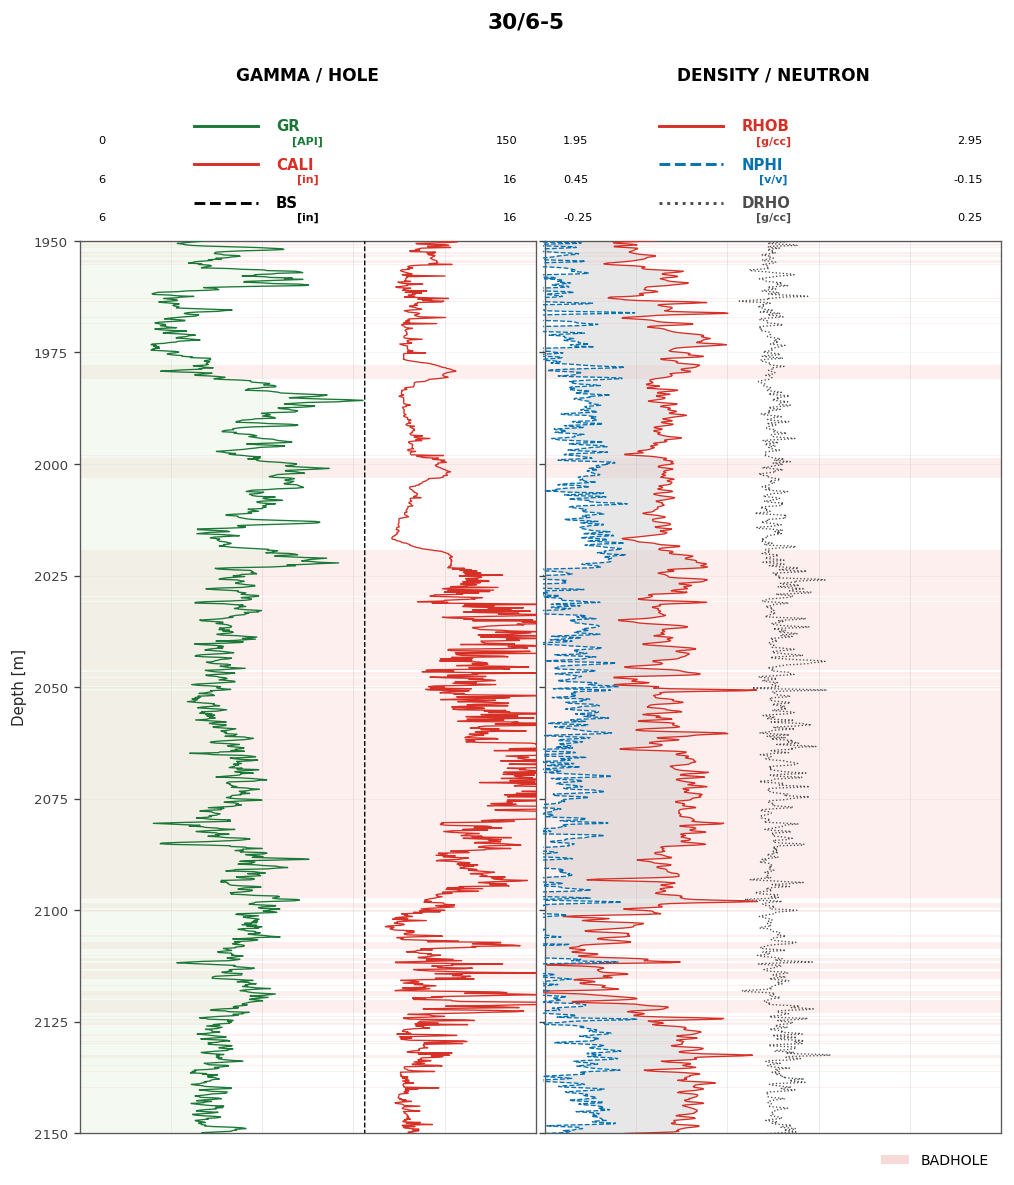

In [13]:
from petrophys.preprocessing import WashoutDetection

WashoutDetection().add_flags_to_well(w)
pp.plot(w, top=1950, bottom=2150, curves=["GR", "CALI", "BS", "RHOB", "NPHI", "DRHO"], figsize=(8, 10))

### The bad-hole thresholds as interpretation settings

The three tests above - $\mathrm{CALI}-\mathrm{BS} > 1.5$ in, $|\mathrm{DRHO}| > 0.15$ g/cm3,
and $\mathrm{BS} > 17.5$ in for large hole - are also the defaults of the `bad_hole` step of
`pp.interpret`, and its BAD_HOLE curve uses only these three. Each is a setting:
`bad_hole={"cali": ..., "drho": ..., "large_hole": ...}` (in, g/cm3, in) takes the ones you
change and keeps the rest. The step's trace records them, and the bad-hole band of
`pp.plot` follows the BAD_HOLE curve the run writes.

Pick a threshold from the tool and the hole, not from the flagged percentage you would
like. The table below gives the 10th percentile and median of CALI - BS for each bit size.
In 30/6-5's 12.25-in hole the caliper reads about 0.75 in over bit size even at its
tightest (the 10th percentile). If that offset is the caliper's
calibration - check it against a casing reading - a 1.5-in washout is measured from it:
`cali` 2.25 in. The 8.5-in hole reads in gauge (10th percentile +0.09 in), though, so a
whole-well 2.25 in would miss washouts there. In the 26-in and 36-in sections the caliper
reads 11-12 in below bit size: it cannot open that wide (its maximum reading is 24.1 in),
so it says nothing about those holes.

In [14]:
w.to_dataframe().assign(CALI_BS=lambda d: d.CALI - d.BS).groupby("BS").CALI_BS.quantile([0.1, 0.5]).unstack()

,0.1,0.5
BS,,
8.50,0.0860,2.141
12.25,0.7580,1.266
17.50,0.4220,1.250
26.00,-12.4475,-10.656
36.00,-11.9370,-11.922


Two interpretations show the effect: the default and `bad_hole={"cali": 2.25}`. The
first table gives the share of samples BAD_HOLE flags in the 12.25-in section
(1815-2805 m) and over the whole well; the second lists the decisions the `bad_hole` step
recorded for the 2.25-in run.

In [15]:
default = pp.interpret(w)
looser = pp.interpret(w, bad_hole={"cali": 2.25})   # 1.5 in beyond the ~0.75 in offset
pd.DataFrame({name: {"12.25-in hole": run.well["BAD_HOLE"].depth_slice(1815, 2805).mean(),
                     "whole well": run.well["BAD_HOLE"].mean()}
              for name, run in [("cali 1.5 in", default), ("cali 2.25 in", looser)]})

,cali 1.5 in,cali 2.25 in
12.25-in hole,0.407482,0.189501
whole well,0.569580,0.445391


In [16]:
looser.step("bad_hole").decisions

['Bad-hole thresholds set: cali=2.25',
 '9877 bad-hole samples flagged out of 22176']

A LAS header can set each threshold - `BADHOLE_CALI`, `BADHOLE_DRHO`, `BADHOLE_BS` - for
the well or for one header zone (`BADHOLE_CALI_Z1` with `TOP_Z1`/`BOT_Z1`). The next cell
sets the zone form with `set_parameter`, the same as the header line
`BADHOLE_CALI_Z1.in 2.25 : ...`, so only the 12.25-in section changes and the 8.5-in hole
keeps the 1.5-in test. A value passed to `interpret` wins over the header.

In the 12.25-in section the 2.25-in caliper test cuts BAD_HOLE from 41% to 19% of the
samples. Applied to the whole well it also lowers the whole-well share from 57% to 45%;
limited to the header zone it gives 51%, because the 8.5-in hole keeps its washouts.

In [17]:
w_zone = pp.read(pp.sample("30_6-5"))
w_zone.set_parameter("BADHOLE_CALI_Z1", 2.25)
w_zone.set_parameter("TOP_Z1", 1815.0)
w_zone.set_parameter("BOT_Z1", 2805.0)
zoned = pp.interpret(w_zone)
zoned.well["BAD_HOLE"].depth_slice(1815, 2805).mean(), zoned.well["BAD_HOLE"].mean()

(0.18950123152709358, 0.505726911976912)

## 4. Multi-well normalization

Even after standardization, a curve's *values* can be biased well-to-well - different tool
calibration, mud, or borehole conditions shift the readings. Before comparing wells (or
applying a single cutoff across a field), we **normalize** to a common scale.

`NormalizationModule().normalize` applies a linear rescale using low/high anchor points
(by default the P5 and P95 percentiles of each curve, robust so outliers do not distort
the fit):

$$\text{norm} = \text{min} + (\text{max}-\text{min})\,\frac{\text{log}-\text{low}}{\text{high}-\text{low}}$$

We use five **COSTA** wells, read in one call from a list of files. First, look at how
their raw GR distributions differ.

In [18]:
costa = pp.read([pp.sample(name) for name in ["HW-3", "HW-4", "HW-5", "HW-6", "HW-7"]])
pd.DataFrame({well.name: well["GR"].describe() for well in costa})

,HW-3,HW-4,HW-5,HW-6,HW-7
count,431.000000,361.000000,337.000000,417.000000,371.000000
null_count,0.000000,0.000000,0.000000,0.000000,0.000000
min,8.130000,7.000000,12.390000,6.620000,5.840000
max,27.320000,44.000000,45.980000,42.850000,49.470000
mean,12.321949,15.429363,20.743472,12.785204,13.314474
std,3.865740,7.955285,9.319079,6.582209,8.319732
median,10.820000,12.000000,16.590000,9.860000,9.630000
p25,9.785000,11.000000,15.390000,8.650000,8.290000
p75,13.875000,15.000000,19.990000,14.400000,14.395000


The distributions drift from well to well: the median runs from 9.6 API (HW-7) to
16.6 API (HW-5), and the maximum from 27.3 API (HW-3) to 49.5 API (HW-7). Each COSTA file
covers the same reservoir zone, Kharaib-2, so we are comparing like with like, although
part of the drift can still be real facies variation (see the pitfalls below). If we
applied a single GR cutoff to pick clean carbonate, it would mean different things in
different wells. Normalizing each well's GR onto **common reference anchors** - mapping
each well's own P5 to 0 and P95 to 100 - removes that bias. Values outside P5-P95 can
remain below 0 or above 100; the transform does not clip them.

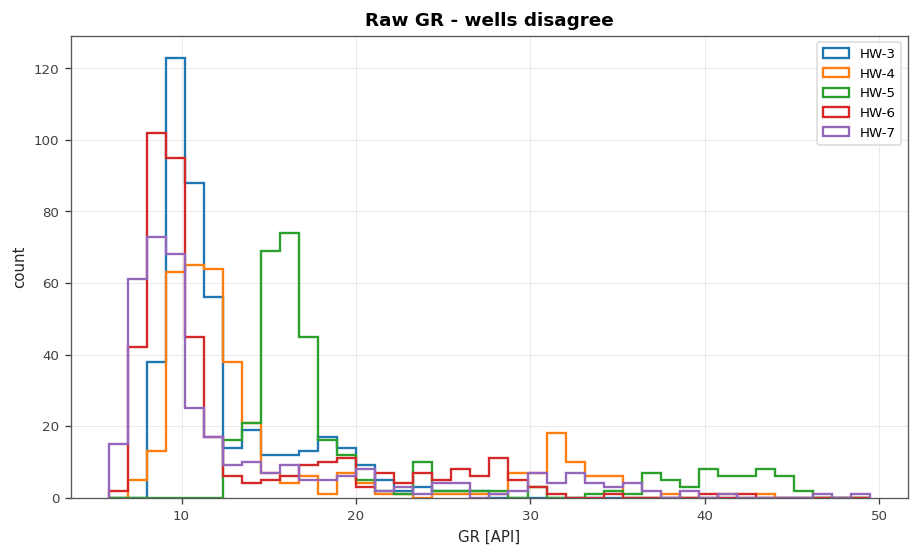

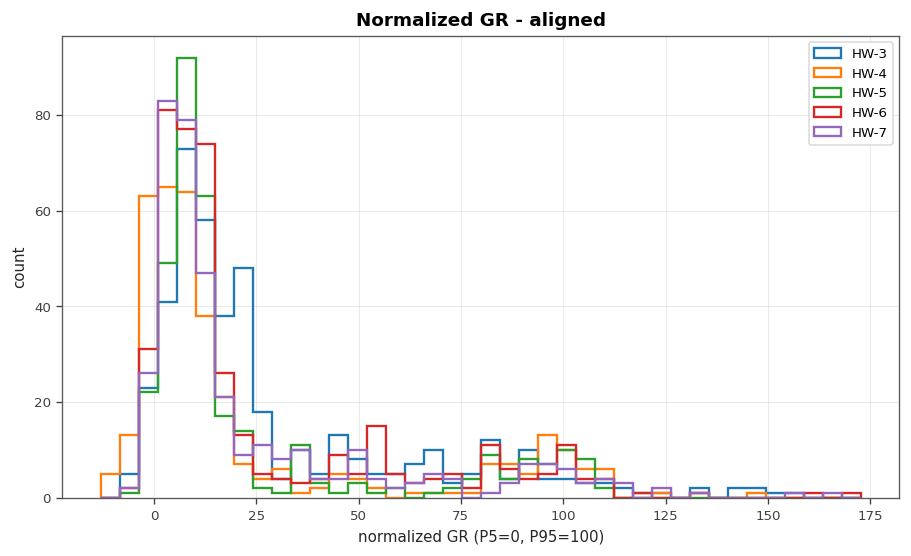

In [19]:
from petrophys.preprocessing import NormalizationModule

normalized = {well.name: NormalizationModule().normalize(well["GR"], 0, 100) for well in costa}
pp.histograms(costa, "GR",
              title="Raw GR - wells disagree", histtype="step")
pp.histograms(normalized, xlabel="normalized GR (P5=0, P95=100)",
              title="Normalized GR - aligned", histtype="step");

The second (normalized) histogram shows the distributions brought into register: a normalized GR of, say,
20 marks the same relative "cleanness" in every well, so a field-wide cutoff behaves
consistently. (Choosing P5/P95 as anchors assumes each well truly samples both clean and
shaly rock - always sanity-check that assumption before normalizing.)

## Pitfalls and parameter choices

- **Standardize first, everything else second.** Bad-hole, value-range, and normalization
  all look curves up by name; if names are inconsistent they silently miss curves.
- **`pp.interpret` standardizes for you.** Its `normalization` step runs this
  standardization by default (`standardize_input` left unset) on the copy of the well it
  interprets: vendor mnemonics get standard aliases (`rename_input_curves=True` renames
  them instead), units are converted, and implausible values are removed with a
  `DataQualityWarning` (from `petrophys.exceptions`). Pass `standardize_input=False` to interpret the curves as read.
- **`standardize_curves` mutates the well.** Load a fresh copy if you need an untouched
  "before" for comparison.
- **Bad-hole needs a bit-size source.** With no header bit size, detection falls back to the
  `BS` curve. With neither, `detect_washout` flags no washout: it applies the `|DRHO|` test only at samples
  that also have a `CALI-BS` value (`bad_hole_flags(..., drho_alone=True)` tests it alone, as the
  workflow's `bad_hole` step does). COSTA wells have no caliper, which is why we demoed
  washout on GeoLink.
- **Value-range QC is curve-specific.** It uses a physical rule per mnemonic, so a
  standardized name is what unlocks the right rule.
- **Normalization anchors are assumptions.** P5/P95 are robust, but if a well never
  penetrates clean rock, forcing its P5 to 0 will over-clean it. Pick anchors that reflect a
  shared geological reference where possible.

## Recap

- **Standardization** (`CurveStandardizer` / `standardize_curves`, `ALIAS_MAP`) maps
  aliases like `DT`/`RT` to standard `DTC`/`RDEP` and normalizes units - do it first.
- **Unit labels can be wrong**: `standardize_core_saturation` infers percent core
  saturation and takes a declared `source_unit`.
- **Value-range QC** (`apply_value_range_qc`, `value_range_qc_note`) nulls or clips
  physically impossible or implausible readings using a per-curve rule table (some
  bounds are physics, others - like RDEP > 2000 ohm.m - are plausibility screens).
- **Bad-hole detection** (`detect_washout` / `WashoutDetection`) flags unreliable
  intervals from `CALI-BS` (and `DRHO`) and attaches the flags as curves;
  `pp.interpret(..., bad_hole={...})` or LAS header parameters set its thresholds.
- **Normalization** (`NormalizationModule`) rescales a curve to a common range across wells so
  field-wide cutoffs are meaningful.
- Always inspect **before/after** and be able to justify each edit physically.

## Try it yourself

> **Exercise 1.** Run `CurveStandardizer().report(...)` on a GeoLink well (e.g. `15_9-14`).
> Which curves are recognized, and are any unit conversions proposed?
>
> **Exercise 2.** Re-run `detect_washout` on `30_6-5` with a stricter caliper threshold
> (`detect_washout(w, cali_threshold=0.75)`). Does the flagged bad-hole percentage go up or
> down, and why?
>
> **Exercise 3.** Normalize `RHOB` (instead of GR) across the five COSTA wells with
> `NormalizationModule().normalize(well["RHOB"], ...)` and overlay the before/after
> histograms. Does density need normalization as much as gamma ray does?

## What's next

That completes the data-conditioning trio (00-02), but **Part A - Foundations** keeps
going: lessons 03 through 09 build the core interpretation science on this clean
foundation - clay/shale volume from the gamma ray (**`03_clay_volume.ipynb`** is next),
then porosity, lithology and mineral solving, formation water, water saturation,
permeability, and reservoir quality / net pay. **Part B** (lessons 10-21) is the
advanced track: the dynamic workflow, formation analysis, core and digital core, ML
imputation, NMR, capillary pressure, borehole images, the visualization masterclass,
the multiwell field study, LLM context generation, the MCP server for LLM agents and
custom workflows.
Everything downstream consumes exactly the conditioned `Well` you have learned to
produce here.